# Exploration de l'annuaire des opérateurs bio (Agence Bio)

**Objectif :** comprendre la source centrale du projet avant de construire les jobs Talend.
Pour chaque colonne, on répond à trois questions :

1. **Que contient-elle ?** Type réel, valeurs possibles.
2. **Quels défauts de qualité a-t-elle ?** Vides, doublons, formats invalides, valeurs aberrantes.
3. **Quelle règle appliquer en silver ?** Garder, corriger, rejeter.

**Source :** `data/raw/agence_bio/2026-11-05/operateursbio.csv` (data.gouv.fr, « Professionnels engagés en BIO », mis à jour chaque jour)

In [1]:
from pathlib import Path

import pandas as pd

# Racine du projet : premier dossier parent qui contient docker-compose.yml
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
ANNUAIRE = RACINE / "data/raw/agence_bio/2026-11-05/operateursbio.csv"
LAPOSTE = RACINE / "data/raw/laposte_codes_postaux/2026-11-05/laposte_hexasmal.csv"

pd.set_option("display.max_colwidth", 80)

## 1. Lecture du fichier

Choix de lecture, à reproduire à l'identique dans Talend (`tFileInputDelimited`) :

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| Séparateur | `;` | Standard français : la virgule sert de séparateur décimal, et ici aussi dans la colonne `ACTIVITES` |
| Encodage | UTF-8 | Vérifié avec la commande `file` |
| Types | tout en texte (`dtype=str`) | En bronze, on ne transforme rien. Et un SIRET ou un code postal n'est **pas un nombre** : `01400` deviendrait `1400` |
| Valeurs vides | ne rien convertir (`keep_default_na=False`) | Par défaut, pandas transforme `"None"` ou `""` en valeur manquante. On veut voir ce que contient **vraiment** le fichier |

In [2]:
brut = pd.read_csv(ANNUAIRE, sep=";", encoding="utf-8", dtype=str, keep_default_na=False)
print(brut.shape)
brut.head()

(88143, 7)


,SIRET,NUMERO BIO,DENOMINATION,CODE POSTAL SIEGE SOCIAL,DATEENGAGEMENT,ACTIVITES,ORGANISME CERTIFICATEUR
0,38459550000024,1,LES PAPILLONS DU LARRY,51120,2020-07-08,"Production,Préparation",Ecocert France
1,52274621300027,3,PINEAU GERALDINE PASCALE ALINE,44430,2019-08-01,"Production,Préparation,Distribution",Bureau Veritas Certification France
2,85219350700013,9,TABURIAUX JONATHAN,32300,2019-07-15,Production,Ecocert France
3,81903659100041,10,AFFAIRES PATISSIERES,69480,2021-06-08,Préparation,Bureau Alpes contrôles
4,41929481400019,11,DA COSTA-AUDEBERT ALAIN PATRICK,37420,2019-07-22,"Production,Préparation",Ecocert France


In [3]:
# Taux de remplissage : combien de valeurs vides (chaîne vide) par colonne ?
pd.DataFrame({
    "vides": (brut == "").sum(),
    "valeurs_distinctes": brut.nunique(),
})

,vides,valeurs_distinctes
SIRET,701,87147
NUMERO BIO,0,88074
DENOMINATION,0,85662
CODE POSTAL SIEGE SOCIAL,0,6075
DATEENGAGEMENT,0,9493
ACTIVITES,0,67
ORGANISME CERTIFICATEUR,0,10


## 2. SIRET

Le **SIRET** identifie un **établissement** (un lieu d'activité) : 14 chiffres = SIREN (9 chiffres, l'entreprise) + NIC (5 chiffres, l'établissement).
C'est la clé de jointure avec SIRENE.

In [4]:
siret = brut["SIRET"]
print("Vides                 :", (siret == "").sum())
print("Pas 14 chiffres       :", ((siret != "") & ~siret.str.fullmatch(r"\d{14}")).sum())
print("En doublon (non vides):", siret[siret != ""].duplicated(keep=False).sum(), "lignes")

Vides                 : 701
Pas 14 chiffres       : 76
En doublon (non vides): 504 lignes


Que contiennent les SIRET qui n'ont pas 14 chiffres ? On affiche leur représentation exacte (`repr`),
qui rend visibles les caractères cachés.

In [5]:
mal_formes = siret[(siret != "") & ~siret.str.fullmatch(r"\d{14}")]
print(mal_formes.value_counts().head(3))
print([repr(s) for s in mal_formes if s != "None"])

SIRET
None               75
41812208100023‬     1
Name: count, dtype: int64
["'41812208100023\\u202c'"]


Deux défauts distincts :
- le **texte `"None"`** à la place d'un SIRET : c'est une valeur manquante déguisée, probablement produite par l'export de l'Agence Bio
  (`None` est la valeur vide de Python). Il faut la traiter comme un vide ;
- un **caractère invisible** `\u202c` (marque de mise en forme Unicode, sans doute issue d'un copier-coller) collé à un SIRET valide.
  Il suffit de ne garder que les chiffres.

### Validité du SIRET : la clé de Luhn

Les 14 chiffres d'un SIRET ne sont pas quelconques : ils respectent l'**algorithme de Luhn**, une somme de contrôle qui détecte les fautes de frappe.

Principe : en partant de la droite, on double un chiffre sur deux (et on retire 9 si le résultat dépasse 9), puis on additionne tout.
Le SIRET est valide si la somme est un multiple de 10.

Exception connue : les établissements de **La Poste** (SIREN `356000000`) suivent une autre règle (somme des chiffres multiple de 5).

In [6]:
def siret_valide(s: str) -> bool:
    if len(s) != 14 or not s.isdigit():
        return False
    if s.startswith("356000000"):          # exception La Poste
        return sum(int(c) for c in s) % 5 == 0
    total = 0
    for i, c in enumerate(reversed(s)):
        n = int(c)
        if i % 2 == 1:                      # un chiffre sur deux, en partant de la droite
            n = n * 2 - 9 if n * 2 > 9 else n * 2
        total += n
    return total % 10 == 0

renseignes = siret[siret != ""]
invalides = renseignes[~renseignes.map(siret_valide)]
print("SIRET renseignés :", len(renseignes), "| invalides (Luhn) :", len(invalides))
invalides.head()

SIRET renseignés : 87442 | invalides (Luhn) : 87


613                None
3609               None
4774               None
6194    41812208100023‬
6722               None
Name: SIRET, dtype: object

### Les doublons de SIRET

Un même SIRET apparaît sur plusieurs lignes. Avant de décider quoi faire, on regarde **ce qui change** entre ces lignes.

In [7]:
doublons = brut[(siret != "") & siret.duplicated(keep=False)].sort_values("SIRET")
print("SIRET concernés :", doublons["SIRET"].nunique(), "| lignes :", len(doublons))

# Pour chaque colonne : dans combien de groupes de doublons la valeur diffère-t-elle ?
colonnes = [c for c in brut.columns if c != "SIRET"]
(doublons.groupby("SIRET")[colonnes].nunique() > 1).sum().rename("groupes_ou_la_valeur_differe")

SIRET concernés : 208 | lignes : 504


NUMERO BIO                  139
DENOMINATION                 58
CODE POSTAL SIEGE SOCIAL     27
DATEENGAGEMENT              197
ACTIVITES                   161
ORGANISME CERTIFICATEUR     115
Name: groupes_ou_la_valeur_differe, dtype: int64

In [8]:
doublons.head(10)

,SIRET,NUMERO BIO,DENOMINATION,CODE POSTAL SIEGE SOCIAL,DATEENGAGEMENT,ACTIVITES,ORGANISME CERTIFICATEUR
86078,10036499100016,306750,Planoulé,09320,None,Distribution,Dispense de certification
86077,10036499100016,306750,Planoulé,09320,2026-05-14,Production,Ecocert France
68131,13003149500018,149943,CHAMBRE D'AGRICULTURE REGION BRETAGNE,35042,1995-03-15,Production,Ecocert France
30470,13003149500018,60641,CHAMBRE D'AGRICULTURE DE REGION BRETAGNE,35042,2013-05-15,Production,Certis
49195,19150599900026,116259,ETABLISSEMENT PUBLIC LOCAL D'ENSEIGNEMENT ET DE FORMATION PROFESSIONNELLE AG...,15100,2022-01-20,Production,Certipaq Bio
49194,19150599900026,116259,ETABLISSEMENT PUBLIC LOCAL D'ENSEIGNEMENT ET DE FORMATION PROFESSIONNELLE AG...,15100,2008-03-17,"Préparation,Distribution",Ecocert France
57007,19790706600017,131182,ETABLISSEMENT PUBLIC LOCAL D'ENSEIGNEMENT ET DE FORMATION PROFESSIONNELLE AG...,79300,1999-01-05,"Production,Préparation",Ecocert France
48597,19790706600017,115293,ETABLISSEMENT PUBLIC LOCAL D'ENSEIGNEMENT ET DE FORMATION PROFESSIONNELLE AG...,79300,2010-01-15,"Préparation,Distribution",Ecocert France
62282,19870581600041,140146,ETABLISSEMENT PUBLIC LOCAL D'ENSEIGNEMENT ET DE FORMATION PROFESSIONNELLE AG...,87430,2017-03-28,Production,Ecocert France
73045,19870581600041,158664,CFPPA LES VASEIX,87430,2001-11-26,Production,Ecocert France


## 3. NUMERO BIO

Le numéro attribué par l'Agence Bio. Est-ce une meilleure clé que le SIRET ?

In [9]:
num = brut["NUMERO BIO"]
print("Vides             :", (num == "").sum())
print("Non numériques    :", (~num.str.fullmatch(r"\d+")).sum())
print("Doublons          :", num.duplicated().sum())
print("Unique par ligne  :", num.is_unique)

Vides             : 0
Non numériques    : 0
Doublons          : 69
Unique par ligne  : False


Le numéro bio n'est pas unique. Regardons ce qui diffère entre les lignes d'un même numéro.

In [10]:
meme_numero = brut[num.duplicated(keep=False)].sort_values("NUMERO BIO")
print("Lignes entièrement identiques dans tout le fichier :", brut.duplicated().sum())
print((meme_numero.groupby("NUMERO BIO").nunique() > 1).sum().rename("groupes_ou_la_valeur_differe"))
meme_numero.head(6)

Lignes entièrement identiques dans tout le fichier : 0
SIRET                        0
DENOMINATION                 0
CODE POSTAL SIEGE SOCIAL     1
DATEENGAGEMENT              68
ACTIVITES                   58
ORGANISME CERTIFICATEUR     67
Name: groupes_ou_la_valeur_differe, dtype: int64


,SIRET,NUMERO BIO,DENOMINATION,CODE POSTAL SIEGE SOCIAL,DATEENGAGEMENT,ACTIVITES,ORGANISME CERTIFICATEUR
41291,78385408600023,103522,ASSOCIATION TRAITS D UNION,59610,2015-01-13,Préparation,Certipaq Bio
41292,78385408600023,103522,ASSOCIATION TRAITS D UNION,59610,2020-01-01,"Production,Distribution",Ecocert France
43432,33378497300013,107341,DU BLANC VERGER,44240,2015-04-10,"Production,Préparation",Certipaq Bio
43433,33378497300013,107341,DU BLANC VERGER,44240,None,Distribution,Dispense de certification
45761,49009319200022,110980,SARL,04300,2003-07-02,Préparation,Ecocert France
45762,49009319200022,110980,SARL,04300,2026-08-11,Préparation,Bureau Alpes contrôles


**Découverte importante sur le grain du fichier.**

Le **grain** d'une table, c'est ce que représente une ligne. Ici, une ligne n'est **pas un opérateur** :
un même opérateur (même numéro bio, même SIRET, même nom) peut avoir **deux lignes**, avec des dates, des activités
et des organismes différents. Il s'agit de deux certifications, par exemple une chez Certipaq pour la préparation
et une autre chez Ecocert pour la production.

Il n'y a aucune ligne entièrement identique : ce ne sont pas de « vrais » doublons à supprimer.
Conséquence pour le modèle : en silver, on sépare l'**opérateur** (une ligne par numéro bio)
de ses **certifications** (une ligne par organisme, date et activités).

## 4. DENOMINATION : attention, données personnelles

Beaucoup d'opérateurs sont des **entrepreneurs individuels** : leur dénomination est leur **nom et leurs prénoms**.
C'est une donnée personnelle au sens du RGPD. On estime leur part grâce à un indice simple :
l'absence de forme juridique (EARL, GAEC, SARL, SCEA, SAS…) dans la dénomination.

In [11]:
FORMES = r"\b(?:EARL|GAEC|SARL|SAS|SASU|SCEA|SCA|SCI|SA|EURL|SNC|SICA|CUMA|SCOP|GFA|ASSOCIATION|COOPERATIVE|DOMAINE|CHATEAU|FERME)\b"
den = brut["DENOMINATION"].str.upper()
sans_forme = ~den.str.contains(FORMES, regex=True)
print(f"Dénominations sans forme juridique : {sans_forme.mean():.0%}  (probables personnes physiques)")
brut.loc[sans_forme, "DENOMINATION"].sample(5, random_state=1)

Dénominations sans forme juridique : 77%  (probables personnes physiques)


86769           PUBLIDIS
36092    VINCENT Anthony
12677           ACAPELLA
20539    BERTON PHILIPPE
9921        VADOT PIERRE
Name: DENOMINATION, dtype: object

C'est une **estimation haute** : des sociétés sans forme juridique dans leur nom (`PUBLIDIS`, `ACAPELLA`) sont comptées à tort.
Mais l'ordre de grandeur suffit pour la décision : **la majorité des dénominations peuvent être des noms de personnes**.
Elles resteront en silver (accès restreint) et ne sortiront jamais en gold.
On note aussi des dénominations inutilisables, comme `SARL` tout court.

## 5. CODE POSTAL SIEGE SOCIAL

Deux contrôles : le **format** (5 chiffres), puis l'**existence** dans la base officielle de La Poste.

La base de La Poste a deux pièges de lecture, à reproduire dans Talend :
- elle est encodée en **ISO-8859-1** (latin-1), et non en UTF-8 ;
- sa ligne d'en-tête commence par `#`.

In [12]:
laposte = pd.read_csv(LAPOSTE, sep=";", encoding="latin-1", dtype=str)
laposte.columns = [c.lstrip("#") for c in laposte.columns]
print(laposte.shape)
laposte.head(3)

(39192, 5)


,Code_commune_INSEE,Nom_de_la_commune,Code_postal,Libellé_d_acheminement,Ligne_5
0,01001,L ABERGEMENT CLEMENCIAT,01400,L ABERGEMENT CLEMENCIAT,NaN
1,01002,L ABERGEMENT DE VAREY,01640,L ABERGEMENT DE VAREY,NaN
2,01004,AMBERIEU EN BUGEY,01500,AMBERIEU EN BUGEY,NaN


In [13]:
cp = brut["CODE POSTAL SIEGE SOCIAL"]
format_ok = cp.str.fullmatch(r"\d{5}")
connus = set(laposte["Code_postal"])
print("Format invalide            :", (~format_ok).sum())
print("Inconnus de La Poste       :", (format_ok & ~cp.isin(connus)).sum())
print("Exemples inconnus          :", sorted(cp[format_ok & ~cp.isin(connus)].unique())[:15])

Format invalide            : 5


Inconnus de La Poste       : 424
Exemples inconnus          : ['01007', '04107', '06201', '06225', '06227', '06296', '06322', '06357', '06515', '06606', '07501', '07720', '07730', '10121', '10403']


In [14]:
# Les codes postaux au format invalide, en représentation exacte
[repr(c) for c in cp[~format_ok]]

["'13420 '", "'42000 '", "'42000 '", "'8850'", "'42000 '"]

Deux défauts réparables :
- des **espaces en fin de valeur** (`'42000 '`) : il faut supprimer les espaces autour (`trim`) ;
- un **zéro initial perdu** (`'8850'` au lieu de `'08850'`, dans les Ardennes) : c'est typique d'un passage par Excel,
  qui prend le code postal pour un nombre. Il faut compléter à gauche par des zéros jusqu'à 5 caractères.

In [15]:
cp_nettoye = cp.str.strip().str.zfill(5)
inconnus = cp_nettoye[~cp_nettoye.isin(connus)]
print("Inconnus après nettoyage :", len(inconnus))
inconnus.value_counts().head(8)

Inconnus après nettoyage : 425


CODE POSTAL SIEGE SOCIAL
92116    104
74162     13
66031      5
66030      4
94587      4
94535      4
26958      3
06201      3
Name: count, dtype: int64

Les codes restants sont surtout des codes **CEDEX** (`92116` = Clichy CEDEX, `74162`…) : des codes réservés aux entreprises
qui reçoivent beaucoup de courrier, absents de la base de La Poste utilisée ici.
Pour eux, on se rabat sur le **département**, déduit des premiers chiffres du code postal.

### Un code postal, plusieurs communes

Un code postal peut couvrir **plusieurs communes**. La jointure code postal → commune n'est donc pas toujours unique :
il faudra une règle (par exemple, garder le département, qui est presque toujours le même).

In [16]:
communes_par_cp = laposte.groupby("Code_postal")["Code_commune_INSEE"].nunique()
departements_par_cp = laposte.assign(dep=laposte["Code_commune_INSEE"].str[:2]).groupby("Code_postal")["dep"].nunique()

cp_operateurs = cp[cp.isin(connus)]
print(f"Opérateurs dont le CP couvre plusieurs communes : {(cp_operateurs.map(communes_par_cp) > 1).mean():.0%}")
print(f"Opérateurs dont le CP couvre plusieurs départements : {(cp_operateurs.map(departements_par_cp) > 1).sum()}")

Opérateurs dont le CP couvre plusieurs communes : 81%
Opérateurs dont le CP couvre plusieurs départements : 347


### Le département ne se lit pas toujours dans les 2 premiers chiffres

- **Corse :** codes postaux `20xxx`, mais départements `2A` et `2B`
- **Outre-mer :** codes postaux `97xxx`, départements sur 3 chiffres (`971` à `976`)
- Quelques codes postaux sont rattachés à un département voisin

D'où l'intérêt de passer par la commune INSEE de La Poste plutôt que de découper le code postal.

In [17]:
print("Codes postaux corses (20xxx)  :", cp.str.startswith("20").sum())
print("Codes postaux d'outre-mer (97x) :", cp.str.startswith("97").sum())

Codes postaux corses (20xxx)  :

 799


Codes postaux d'outre-mer (97x) : 1369


## 6. DATEENGAGEMENT

In [18]:
date_txt = brut["DATEENGAGEMENT"]
dates = pd.to_datetime(date_txt, format="%Y-%m-%d", errors="coerce")
print("Valeurs non convertibles :", dates.isna().sum(), "→", date_txt[dates.isna()].value_counts().to_dict())
print("Plus ancienne            :", dates.min().date())
print("Plus récente             :", dates.max().date())
print("Dans le futur            :", (dates > pd.Timestamp("2026-11-05")).sum())

Valeurs non convertibles :

 1322 → {'None': 1322}
Plus ancienne            : 1994-06-08
Plus récente             : 2027-01-01
Dans le futur            : 6


In [19]:
# Les dates manquantes : qui sont ces opérateurs ?
brut.loc[dates.isna(), "ORGANISME CERTIFICATEUR"].value_counts()

ORGANISME CERTIFICATEUR
Dispense de certification    1322
Name: count, dtype: int64

In [20]:
# Les dates dans le futur
brut.loc[dates > pd.Timestamp("2026-11-05"), ["NUMERO BIO", "DATEENGAGEMENT", "ACTIVITES", "ORGANISME CERTIFICATEUR"]]

,NUMERO BIO,DATEENGAGEMENT,ACTIVITES,ORGANISME CERTIFICATEUR
85441,305992,2026-12-18,"Production,Préparation",Bureau Alpes contrôles
87176,308281,2027-01-01,Production,Bureau Veritas Certification France
87454,308676,2027-01-01,Préparation,Certipaq Bio
87473,308702,2027-01-01,Distribution,Certipaq Bio
87936,309916,2027-01-01,"Préparation,Distribution",Certipaq Bio
88100,310264,2027-01-01,Préparation,Certipaq Bio


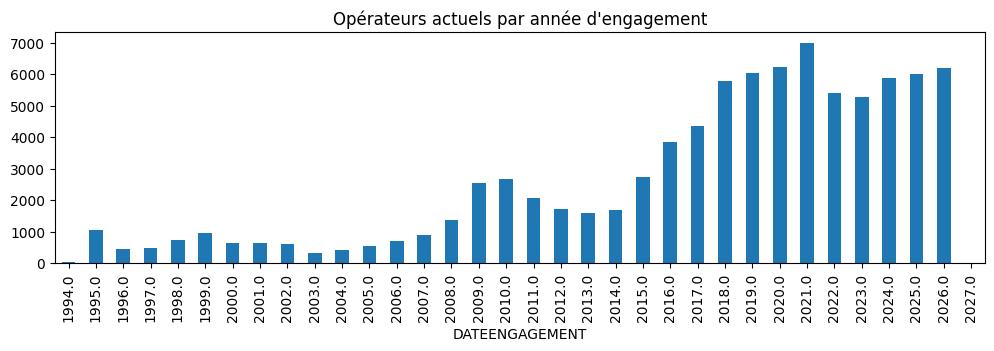

In [21]:
# Engagements par année : la dynamique de la filière (axe 2)
dates.dt.year.value_counts().sort_index().plot(kind="bar", figsize=(12, 3), title="Opérateurs actuels par année d'engagement");

## 7. ACTIVITES : une colonne multi-valuée

Une cellule contient plusieurs activités séparées par des virgules (`Production,Préparation`).
C'est contraire à la **première forme normale** (1FN) : une cellule = une seule valeur.
En silver, on « éclate » la colonne : une ligne par couple opérateur × activité (`explode` en pandas, `tNormalize` dans Talend).

In [22]:
activites = brut.assign(ACTIVITE=brut["ACTIVITES"].str.split(",")).explode("ACTIVITE")
activites["ACTIVITE"] = activites["ACTIVITE"].str.strip()
print("Lignes après éclatement :", len(activites), "(pour", len(brut), "opérateurs)")
print("Activités vides :", (activites["ACTIVITE"] == "").sum())
activites["ACTIVITE"].value_counts()

Lignes après éclatement : 134264 (pour 88143 opérateurs)
Activités vides : 0


ACTIVITE
Production      61992
Préparation     42096
Distribution    21543
Stockage         7054
Importation       901
Exportation       495
Restauration      178
Transport           5
Name: count, dtype: int64

In [23]:
# Nombre d'activités par opérateur
brut["ACTIVITES"].str.count(",").add(1).value_counts().sort_index().rename("operateurs")

ACTIVITES
1    50797
2    29767
3     6433
4     1098
5       46
6        2
Name: operateurs, dtype: int64

## 8. ORGANISME CERTIFICATEUR

In [24]:
brut["ORGANISME CERTIFICATEUR"].value_counts().to_frame("operateurs").assign(
    part=lambda d: (d["operateurs"] / d["operateurs"].sum()).round(3)
)

,operateurs,part
ORGANISME CERTIFICATEUR,,
Ecocert France,48950,0.555
Bureau Veritas Certification France,18814,0.213
Certipaq Bio,8388,0.095
Qualisud,3512,0.040
Bureau Alpes contrôles,3485,0.040
Certisud,2009,0.023
Dispense de certification,1322,0.015
Certis,1043,0.012
Ocacia,483,0.005


## 9. Synthèse : règles pour la couche silver

### Le grain

Une ligne du fichier = **une certification** d'un opérateur, et non un opérateur.
En silver, on sépare donc :
- **opérateur** : une ligne par `NUMERO BIO` (identité, SIRET, code postal) ;
- **certification** : une ligne par ligne du fichier. Aucune combinaison de colonnes n'est unique
  (même numéro bio + organisme + date peut apparaître deux fois, avec un code postal différent).
  On crée donc une **clé technique** : une empreinte (*hash*) de toutes les colonnes de la ligne.
  Elle est unique, car aucune ligne n'est entièrement identique, et stable d'un jour à l'autre :
  une ligne inchangée garde la même empreinte, ce qui permet de détecter les changements pour l'historique SCD 2 ;
- **certification_activite** : une ligne par certification × activité (colonne `ACTIVITES` éclatée, première forme normale).

### Règles par colonne

| Colonne | Constat | Règle en silver |
|---|---|---|
| `SIRET` | 701 vides, 75 `"None"`, 1 caractère invisible, 11 invalides selon Luhn, 208 SIRET partagés par plusieurs numéros bio | Ne garder que les chiffres. `"None"` et vide deviennent NULL. Contrôle de Luhn : un SIRET invalide devient NULL, la ligne est gardée et l'anomalie est tracée dans `audit.rejet`. Pas de dédoublonnage sur le SIRET |
| `NUMERO BIO` | Toujours renseigné et numérique. 69 numéros sur 2 lignes (2 certifications) | Clé de l'opérateur |
| `DENOMINATION` | Majorité de noms de personnes probables (RGPD). Quelques valeurs inutilisables (`SARL`) | Gardée en silver uniquement (accès restreint). Jamais exposée en gold |
| `CODE POSTAL` | 4 avec espaces, 1 sans zéro initial, ~420 CEDEX absents de La Poste | `trim`, puis compléter à 5 caractères. Jointure avec La Poste pour la commune. À défaut (CEDEX), département déduit du code postal (règles particulières pour la Corse et l'outre-mer) |
| `DATEENGAGEMENT` | 1 322 `"None"`, tous « Dispense de certification ». 6 dates dans le futur | `"None"` devient NULL (cas normal : opérateurs dispensés). Une date future est gardée, mais signalée dans `audit.rejet` |
| `ACTIVITES` | Multi-valuée, 8 activités, 1 à 6 par ligne | Éclatée en lignes (`tNormalize` dans Talend). Référentiel `activite` |
| `ORGANISME CERTIFICATEUR` | 10 valeurs, dont « Dispense de certification » (ce n'est pas un organisme) | Référentiel `certificateur`, avec un indicateur `est_dispense` |

### Pour Talend

- Lecture : séparateur `;`, UTF-8, en-tête sur la première ligne, toutes les colonnes en `String` en bronze.
- Base de La Poste : **ISO-8859-1**, et en-tête précédé d'un `#`.
- Composants pressentis : `tFileInputDelimited`, `tMap` (nettoyage et jointures), `tNormalize` (activités),
  `tUniqRow` (opérateurs), `tJava` ou une routine (contrôle de Luhn), `tDBOutput` (PostgreSQL), et un flux de rejets vers `audit.rejet`.